<a href="https://colab.research.google.com/github/ProNob4/CodeAlpha_ProjectPronob/blob/main/Sales_Prediction_using_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset Overview:
      TV  radio  newspaper  sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3    9.3
3  151.5   41.3       58.5   18.5
4  180.8   10.8       58.4   12.9


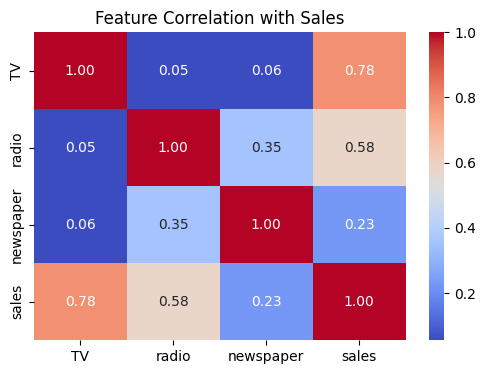

--- Linear Regression ---
R² Score: 0.899
RMSE: 1.782

--- Random Forest Regressor ---
R² Score: 0.981
RMSE: 0.769


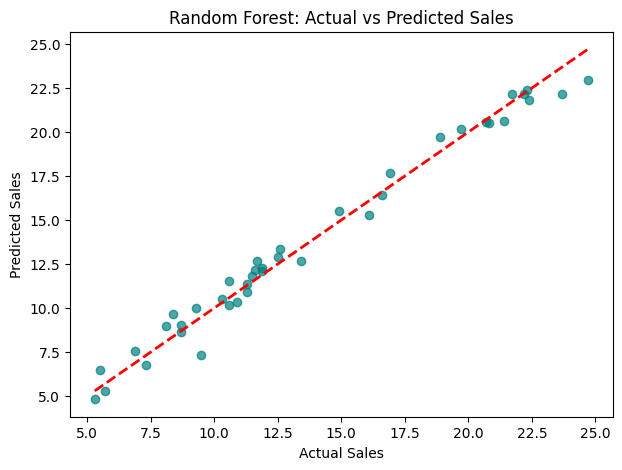

In [2]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# 2. Load dataset (Standard Advertising dataset)
url = "https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv"
df = pd.read_csv(url)

# Drop any unneeded index column if present
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print("Dataset Overview:")
print(df.head())

# 3. Correlation Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Feature Correlation with Sales")
plt.show()

# 4. Train-Test Split
X = df[['TV', 'radio', 'newspaper']]
y = df['sales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Fit Linear Regression & Random Forest Models
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

# 6. Evaluation
print("--- Linear Regression ---")
print(f"R² Score: {r2_score(y_test, lr_preds):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, lr_preds)):.3f}")

print("\n--- Random Forest Regressor ---")
print(f"R² Score: {r2_score(y_test, rf_preds):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, rf_preds)):.3f}")

# 7. Prediction vs Actual Plot
plt.figure(figsize=(7, 5))
plt.scatter(y_test, rf_preds, color='teal', alpha=0.7)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Random Forest: Actual vs Predicted Sales")
plt.show()